# Data pre-processing

In [ ]:
# Libraries
import pandas as pd
import scipy.stats as stats

This cell imports the libraries needed for the analysis. `pandas` is used to work with tabular data, and `scipy.stats` provides statistical tests such as t-tests, ANOVA, and chi-square tests.

In [ ]:
# Load dataset
df = pd.read_csv('/content/cellphone_data.csv')

This cell loads the cellphone dataset from a CSV file into a DataFrame named `df`. Make sure the file path matches where you uploaded or saved the CSV file.

 **Perform Other Data Pre-processing steps below such as checking data description, null values etc.**


In [ ]:
# First look
df.head()

,user_id,cellphone_id,rating,brand,model,operating system,internal memory,RAM,performance,main camera,...,screen size,weight,price(INR),release date,user_name,Region(City),Salary_in_INR,age,gender,occupation
0,0,30,1,Motorola,Moto G Play (2021),Android,32,3,1.42,13,...,6.5,204,13888.65,14/01/2021,Ram,Delhi,570500,38,Female,Data analyst
1,0,5,3,Apple,iPhone XR,iOS,64,3,4.22,12,...,6.1,194,20614.60,26/10/2018,Ram,Delhi,570500,38,Female,Data analyst
2,0,10,9,Samsung,Galaxy S22,Android,128,8,8.81,50,...,6.1,167,46120.80,25/02/2022,Ram,Delhi,570500,38,Female,Data analyst
3,0,9,3,Samsung,Galaxy A53,Android,128,6,3.79,64,...,6.5,189,27253.20,24/03/2022,Ram,Delhi,570500,38,Female,Data analyst
4,0,23,2,Vivo,X80 Pro,Android,256,8,9.81,50,...,6.7,215,76169.20,29/04/2022,Ram,Delhi,570500,38,Female,Data analyst


This cell displays the first five rows of the dataset so you can preview the data and check whether it loaded correctly.

In [ ]:
# Shape (rows, columns)
df.shape

(990, 22)

This cell displays the shape of the dataset: the first number is the total number of rows, and the second number is the total number of columns.

In [ ]:
# Column names, data types, non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 990 entries, 0 to 989
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           990 non-null    int64  
 1   cellphone_id      990 non-null    int64  
 2   rating            990 non-null    int64  
 3   brand             990 non-null    object 
 4   model             990 non-null    object 
 5   operating system  990 non-null    object 
 6   internal memory   990 non-null    int64  
 7   RAM               990 non-null    int64  
 8   performance       990 non-null    float64
 9   main camera       990 non-null    int64  
 10  selfie camera     990 non-null    int64  
 11  battery size      990 non-null    int64  
 12  screen size       990 non-null    float64
 13  weight            990 non-null    int64  
 14  price(INR)        990 non-null    float64
 15  release date      990 non-null    object 
 16  user_name         990 non-null    object 
 1

This cell shows each column's name, data type, and number of non-missing values. It helps you understand the structure of the dataset.

In [ ]:
# Summary statistics for numeric columns
df.describe()

,user_id,cellphone_id,rating,internal memory,RAM,performance,main camera,selfie camera,battery size,screen size,weight,price(INR),Salary_in_INR,age
count,990.000000,990.000000,990.000000,990.000000,990.000000,990.000000,990.000000,990.000000,990.000000,990.000000,990.000000,990.000000,990.000000,990.000000
mean,136.373737,16.421212,6.691919,145.034343,6.701010,6.013869,42.238384,15.368687,4376.201010,6.452323,198.159596,52641.698081,527464.393939,36.393939
std,80.664654,9.473466,2.616552,89.314731,2.666782,2.867455,26.694386,9.860320,763.260773,0.420758,23.731792,36775.360069,92676.123930,9.634176
min,0.000000,0.000000,1.000000,32.000000,3.000000,1.020000,12.000000,4.000000,2018.000000,4.700000,141.000000,11268.150000,300000.000000,21.000000
25%,74.000000,8.000000,5.000000,128.000000,4.000000,3.790000,12.000000,8.000000,4000.000000,6.400000,183.000000,26117.650000,459375.000000,29.000000
50%,128.000000,16.000000,7.000000,128.000000,8.000000,6.820000,50.000000,12.000000,4600.000000,6.500000,203.000000,43675.000000,486150.000000,33.000000
75%,226.000000,25.000000,9.000000,128.000000,8.000000,7.940000,50.000000,16.000000,5000.000000,6.700000,207.000000,73374.000000,601500.000000,42.000000
max,258.000000,32.000000,10.000000,512.000000,12.000000,11.000000,108.000000,40.000000,5003.000000,7.600000,271.000000,174525.300000,700500.000000,61.000000


This cell calculates summary statistics for numerical columns, including count, mean, standard deviation, minimum, maximum, and quartiles.

In [ ]:
# Missing values per column
df.isnull().sum()

,0
user_id,0
cellphone_id,0
rating,0
brand,0
model,0
operating system,0
internal memory,0
RAM,0
performance,0
main camera,0


This cell counts missing values in every column. A result of zero means that the column has no missing values.

In [ ]:
df.duplicated().sum()

np.int64(0)

This cell counts duplicate rows in the dataset. If the result is greater than zero, duplicate records are present.

In [ ]:
# Drop them if any exist
df = df.drop_duplicates()

This cell removes duplicate rows from `df` so that repeated records do not affect the analysis.

**Split the variables in the dataset into numerical and categorical types.**

In [ ]:
# Split variables by data type
numerical_cols = df.select_dtypes(include='number').columns.tolist()
categorical_cols = df.select_dtypes(include='object').columns.tolist()

print("Numerical variables:", numerical_cols)
print("Categorical variables:", categorical_cols)

Numerical variables: ['user_id', 'cellphone_id', 'rating', 'internal memory', 'RAM', 'performance', 'main camera', 'selfie camera', 'battery size', 'screen size', 'weight', 'price(INR)', 'Salary_in_INR', 'age']
Categorical variables: ['brand', 'model', 'operating system', 'release date', 'user_name', 'Region(City)', 'gender', 'occupation']


This cell separates the column names into numerical variables and categorical variables based on their data types. The lists are used later to select suitable columns for visualizations.

**Create boxplots for all numerical variables to check for outliers.**


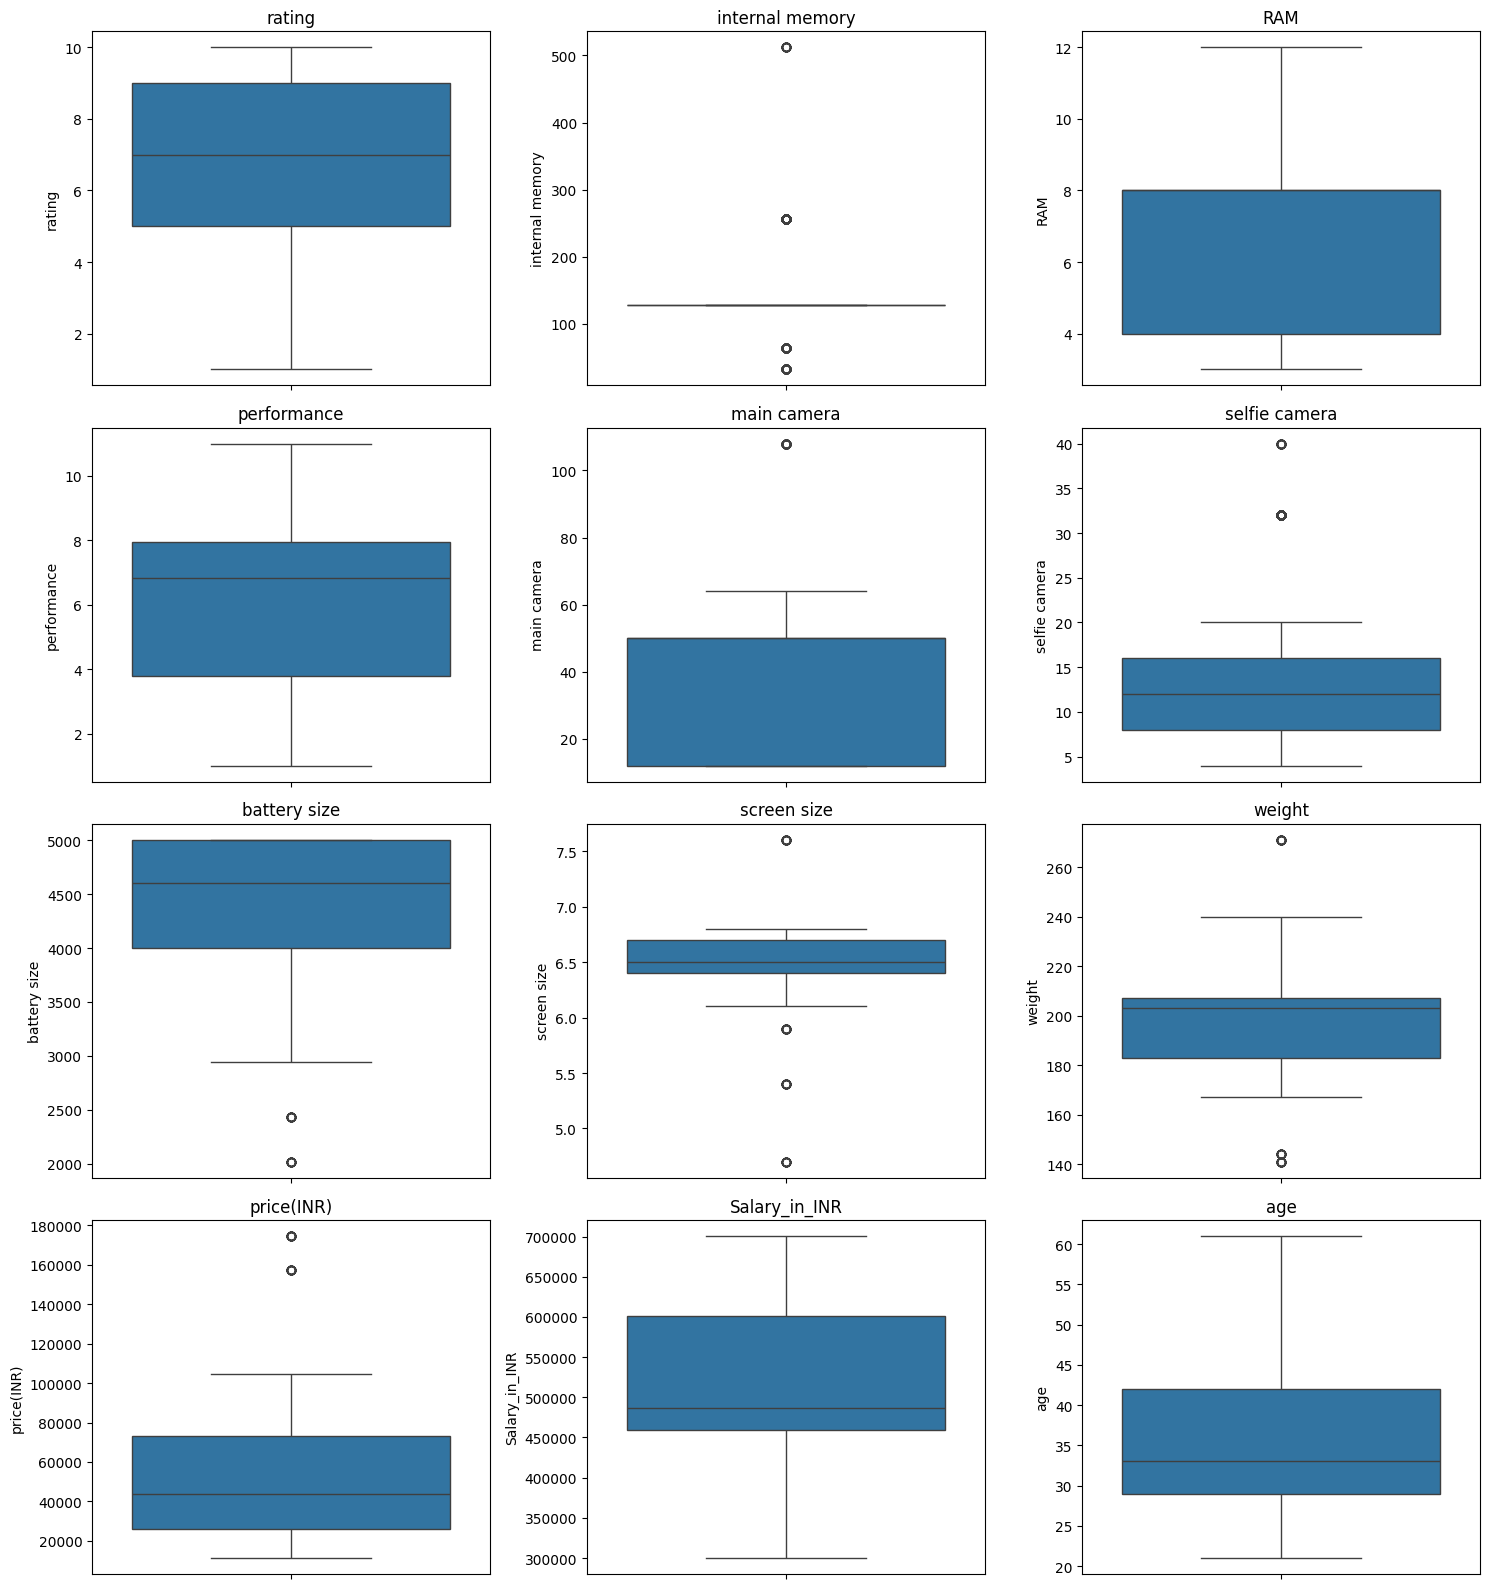

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Exclude ID columns, they are labels, not real measurements
plot_cols = [col for col in numerical_cols if col not in ['user_id', 'cellphone_id']]

# One boxplot per numerical variable, laid out in a grid
n_cols = 3
n_rows = (len(plot_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(plot_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)

# Hide any unused empty subplots
for j in range(len(plot_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

This cell creates boxplots for numerical variables, excluding ID columns. Boxplots help identify possible outliers and compare the spread of values. Points beyond the whiskers may be potential outliers, not automatically errors.

**Generate a heatmap for all numerical variables to examine their correlations.**


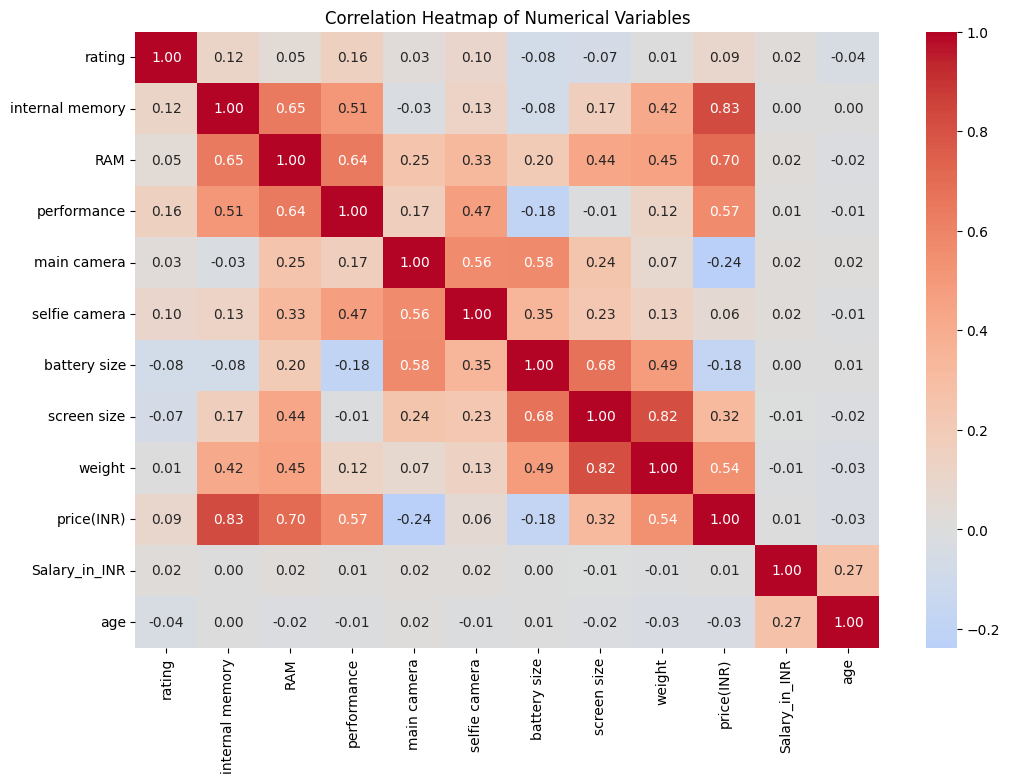

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation matrix (excluding ID columns)
corr = df[plot_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

This cell calculates correlations between numerical variables and displays them as a heatmap. Values near +1 indicate a strong positive relationship, values near -1 indicate a strong negative relationship, and values near 0 indicate a weak linear relationship. Correlation does not prove causation.

**Create count plots for all categorical variables to visualize their distributions.**


Plotted: ['brand', 'operating system', 'Region(City)', 'gender']
Skipped (too many categories): ['model', 'release date', 'user_name', 'occupation']


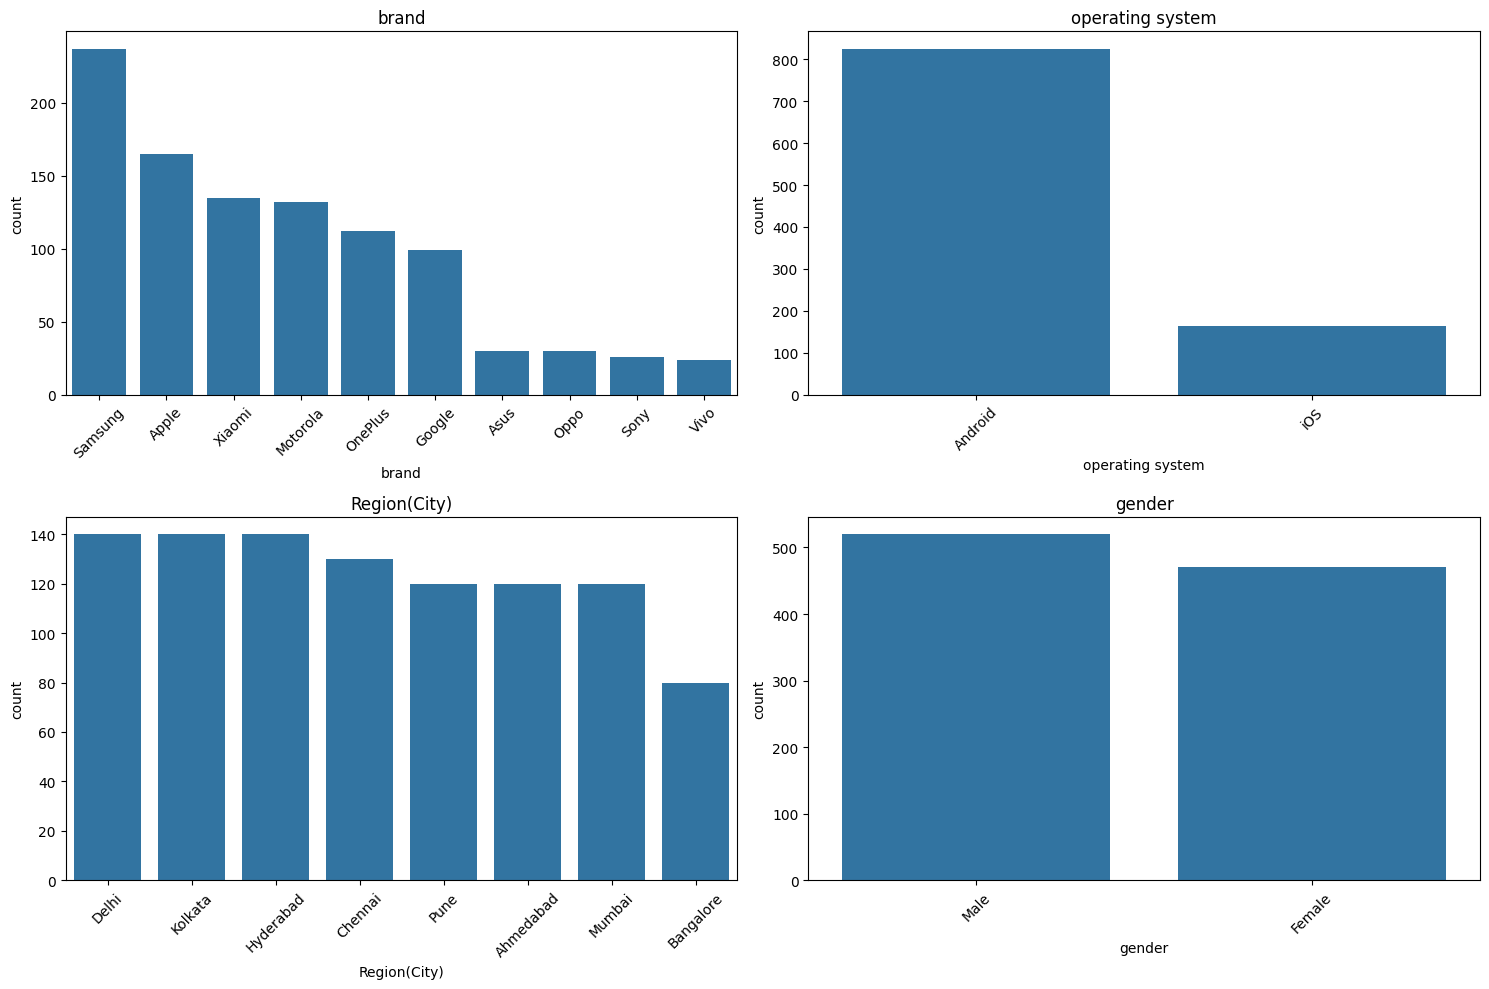

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Skip columns with too many unique values (they make unreadable plots)
plot_cat_cols = [col for col in categorical_cols if df[col].nunique() <= 15]
skipped = [col for col in categorical_cols if df[col].nunique() > 15]
print("Plotted:", plot_cat_cols)
print("Skipped (too many categories):", skipped)

n_cols = 2
n_rows = (len(plot_cat_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(plot_cat_cols):
    sns.countplot(x=df[col], ax=axes[i], order=df[col].value_counts().index)
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=45)

# Hide unused subplots
for j in range(len(plot_cat_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

This cell creates count plots for categorical columns with 15 or fewer unique categories. The plots show how frequently each category occurs. Columns with more than 15 categories are skipped to keep the charts readable. **Coding note:** the final line should be `plt.show()` without the surrounding `**` characters.

**Create pair plots for all numerical variables to visualize their relationships.**


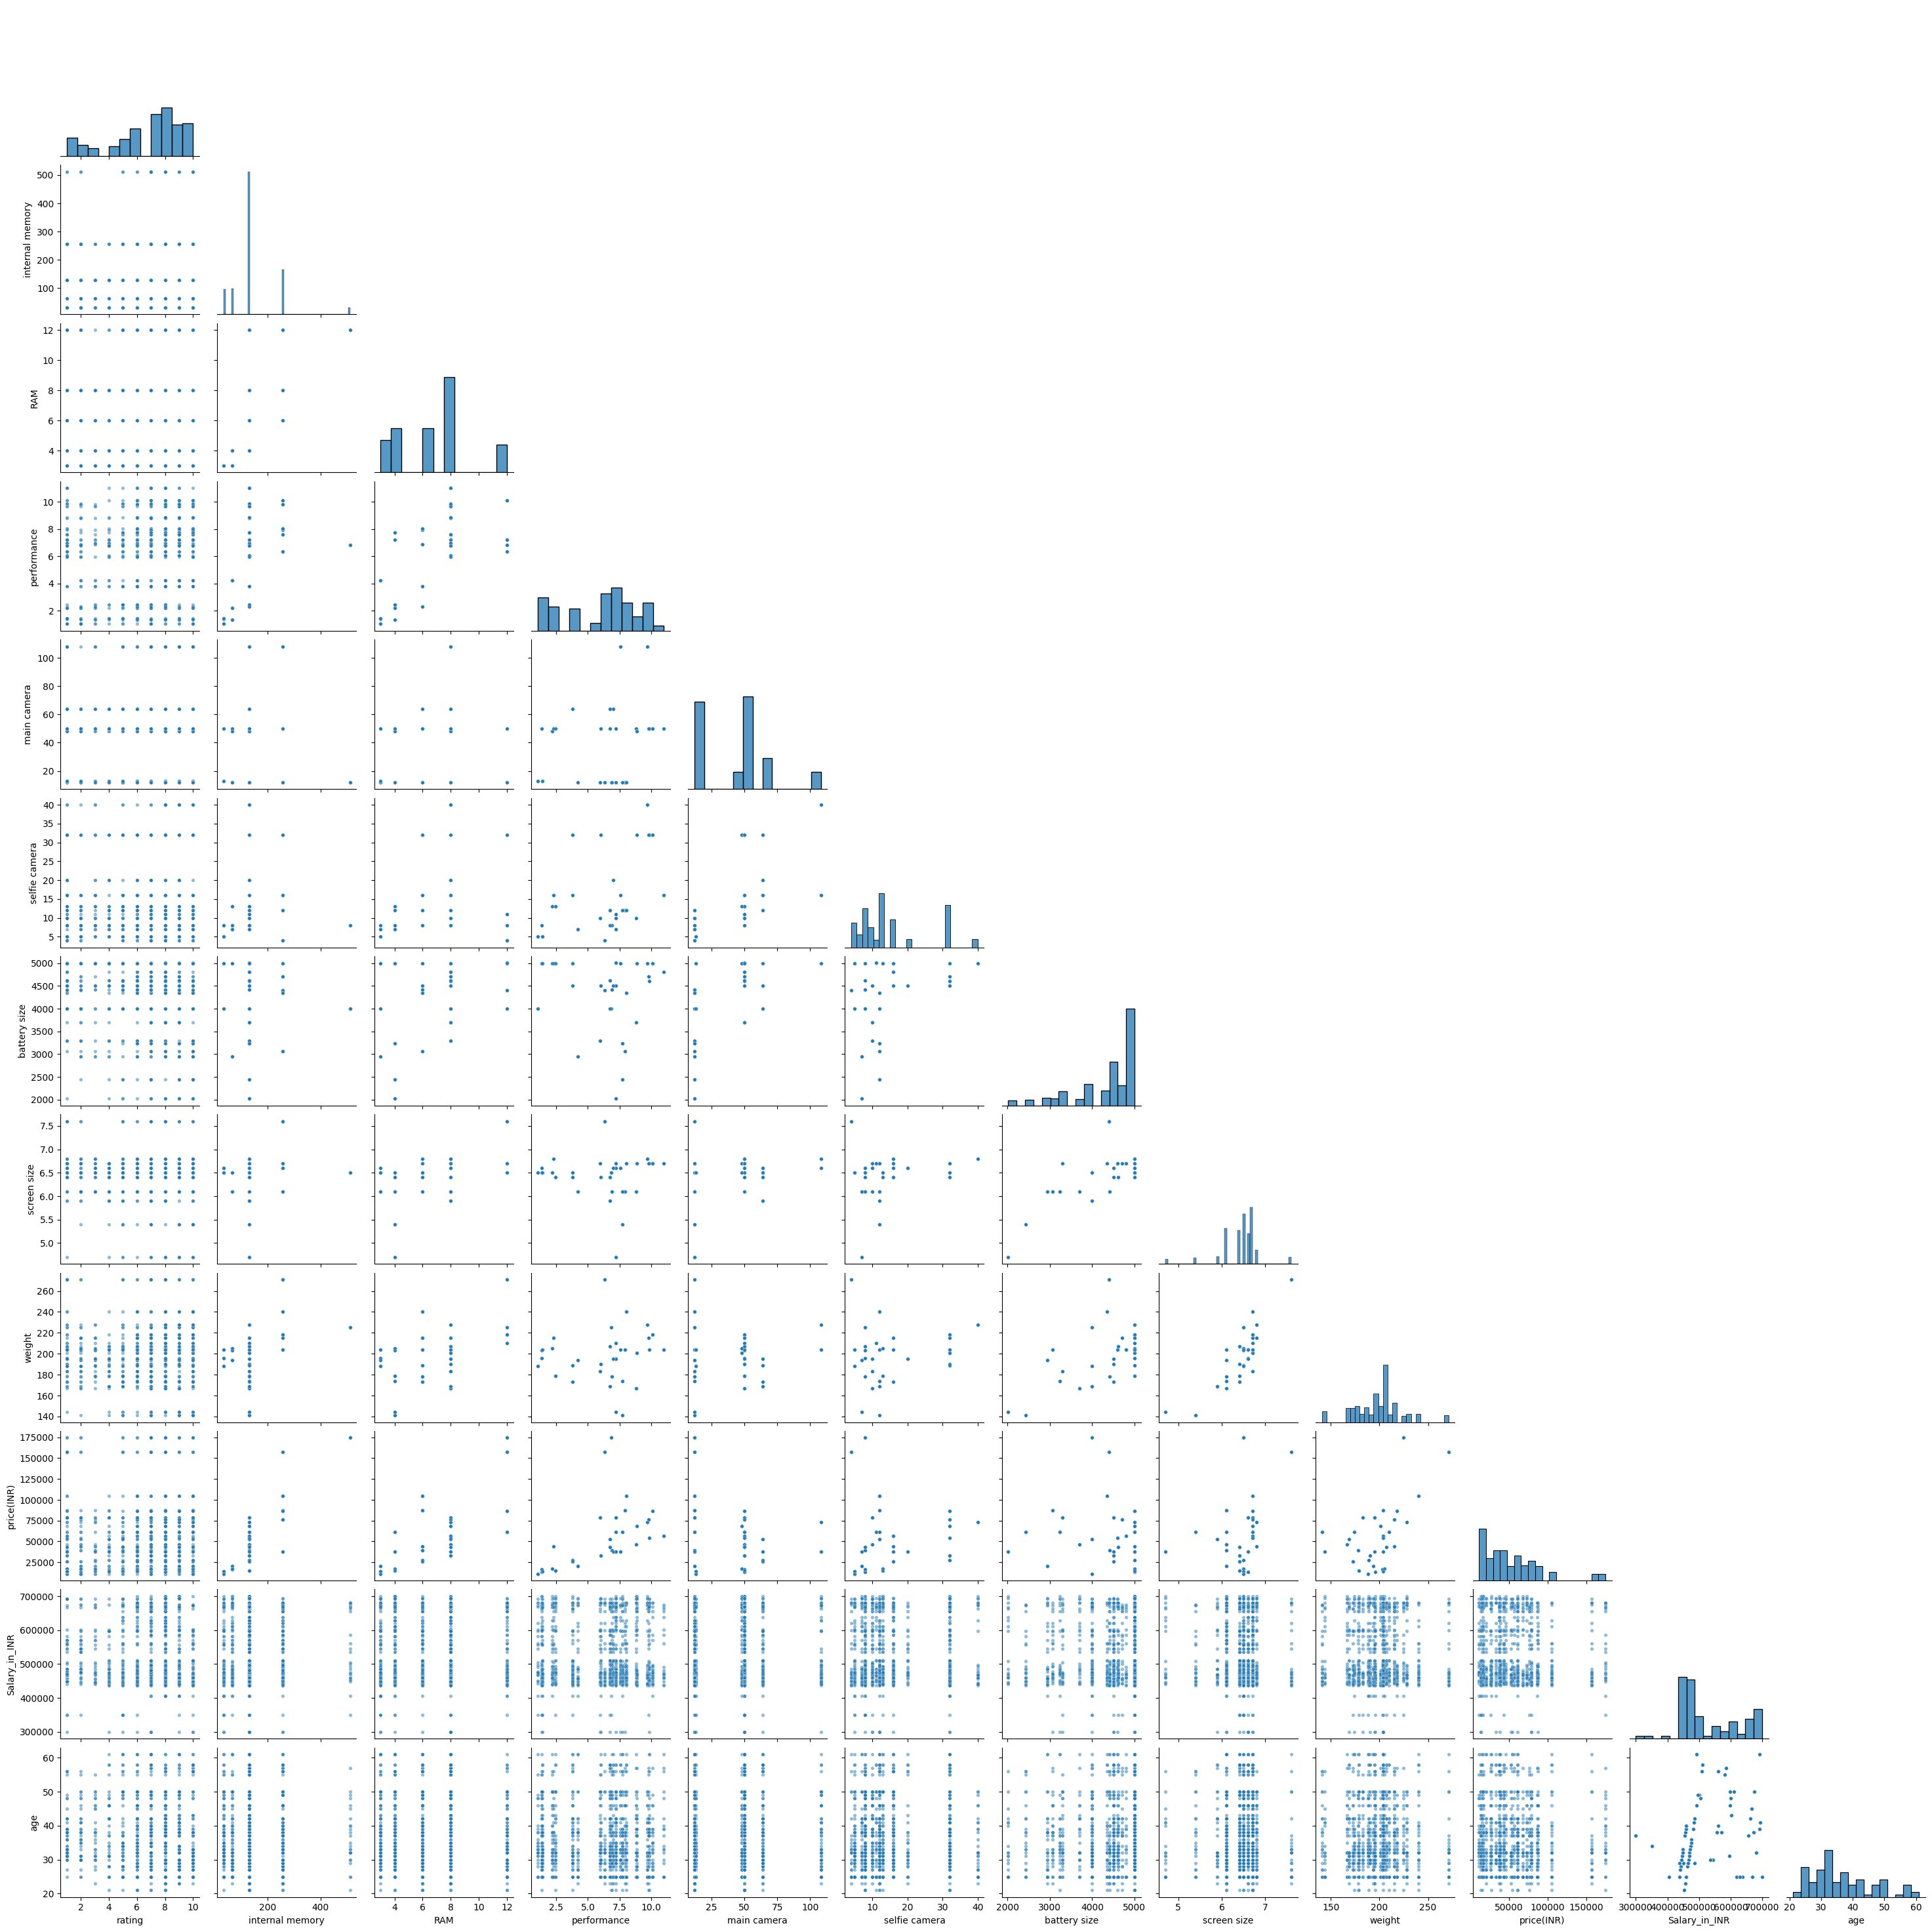

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Same numerical columns as before (IDs excluded)
sns.pairplot(df[plot_cols], corner=True, plot_kws={'alpha': 0.5, 's': 15})
plt.show()

This cell creates pair plots for all selected numerical variables. Each small chart shows the relationship between a pair of variables, while the diagonal shows each variable's distribution.

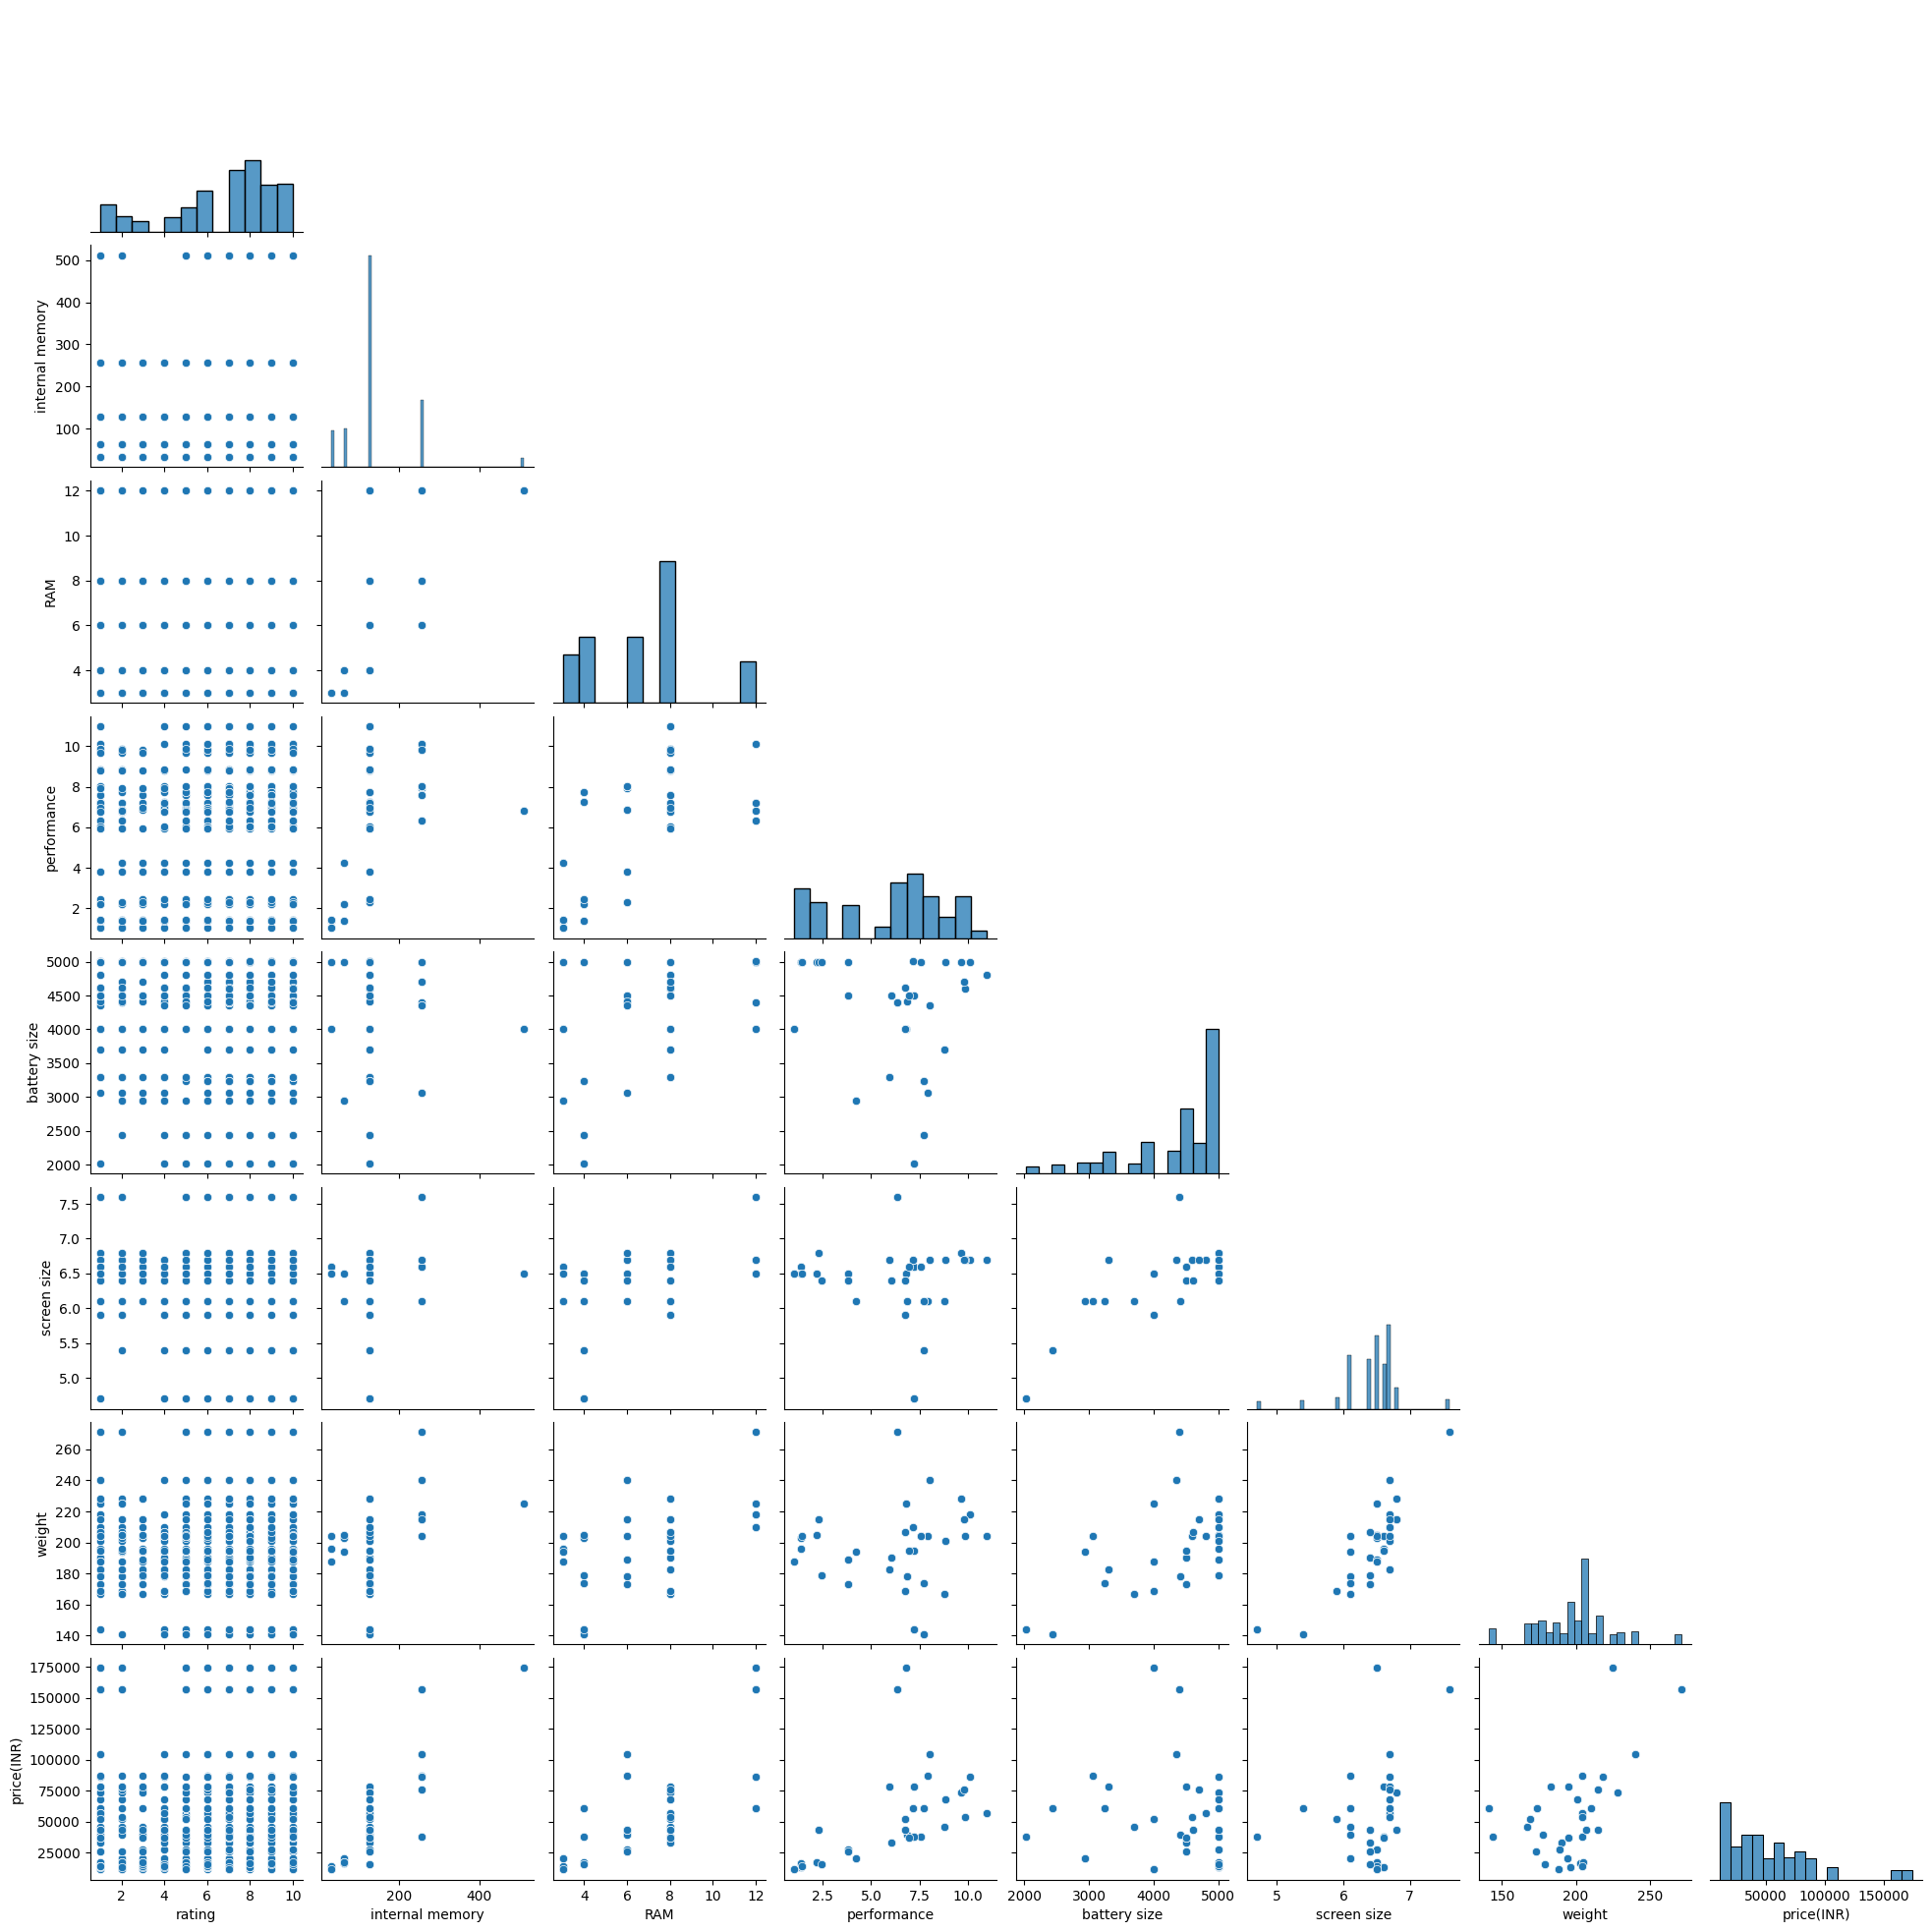

In [ ]:
key_cols = ['rating', 'internal memory', 'RAM', 'performance', 'battery size', 'screen size', 'weight', 'price(INR)']
sns.pairplot(df[key_cols], corner=True)
plt.show()

This cell creates pair plots for selected cellphone features such as rating, memory, RAM, performance, battery size, screen size, weight, and price. It helps visually compare relationships among these important features.

**1. Hypothesis Testing**



1a. Two-sample t-test: Salary difference between genders


In [ ]:
male_salary = df[df['gender']=='Male']['Salary_in_INR']
female_salary = df[df['gender']=='Female']['Salary_in_INR']
t_stat, p_value = stats.ttest_ind(male_salary, female_salary)
print("T-test: Salary difference between genders")
print("t-statistic:", t_stat, "p-value:", p_value, "\n")

T-test: Salary difference between genders
t-statistic: -2.247686529084287 p-value: 0.024816102588423032 



This cell performs an independent two-sample t-test comparing the average salary of male and female customers. The p-value helps assess whether the observed difference is statistically significant. This test assumes the two groups are independent.

1b. One-sample t-test: RAM > 16 GB

In [ ]:
t_stat, p_value = stats.ttest_1samp(df['RAM'], 16, alternative='greater')
print("One-sample t-test: Mean RAM > 16 GB")
print("t-statistic:", t_stat, "p-value:", p_value, "\n")

One-sample t-test: Mean RAM > 16 GB
t-statistic: -109.71494869112836 p-value: 1.0 



This cell performs a one-sample, one-sided t-test to check whether the population mean RAM is greater than 16 GB. A small p-value (commonly below 0.05) provides evidence in favour of the stated alternative hypothesis.

    1c. One-sample t-test: Main camera > 12 MP


In [ ]:
t_stat, p_value = stats.ttest_1samp(df['main camera'], 12, alternative='greater')
print("One-sample t-test: Main camera > 12 MP")
print("t-statistic:", t_stat, "p-value:", p_value, "\n")

One-sample t-test: Main camera > 12 MP
t-statistic: 35.6415218671936 p-value: 6.466166332868273e-180 



This cell performs a one-sample, one-sided t-test to check whether the mean main-camera specification is greater than 12 MP. Use the p-value to assess the evidence for this claim.

1d. Two-sample t-test: Price difference between Android and iOS


In [ ]:
android_price = df[df['operating system']=='Android']['price(INR)']
ios_price = df[df['operating system']=='iOS']['price(INR)']
t_stat, p_value = stats.ttest_ind(android_price, ios_price)
print("T-test: Price difference between Android and iOS")
print("t-statistic:", t_stat, "p-value:", p_value, "\n")

T-test: Price difference between Android and iOS
t-statistic: -4.466996840290052 p-value: 8.848111231308473e-06 



This cell performs an independent two-sample t-test comparing cellphone prices for Android and iOS devices. The p-value indicates whether there is statistical evidence of a difference in the group means.

1e. One-sample t-test: Selfie camera > 8 MP


In [ ]:
t_stat, p_value = stats.ttest_1samp(df['selfie camera'], 8, alternative='greater')
print("One-sample t-test: Selfie camera > 8 MP")
print("t-statistic:", t_stat, "p-value:", p_value, "\n")

One-sample t-test: Selfie camera > 8 MP
t-statistic: 23.51346761866551 p-value: 9.08337997279999e-98 



This cell performs a one-sample, one-sided t-test to check whether the mean selfie-camera specification is greater than 8 MP.

1f. One-sample t-test: Battery size > 4000 mAh


In [ ]:
t_stat, p_value = stats.ttest_1samp(df['battery size'], 4000, alternative='greater')
print("One-sample t-test: Battery size > 4000 mAh")
print("t-statistic:", t_stat, "p-value:", p_value, "\n")

One-sample t-test: Battery size > 4000 mAh
t-statistic: 15.508314925000109 p-value: 5.106907137628001e-49 



This cell performs a one-sample, one-sided t-test to check whether the mean battery size is greater than 4000 mAh.

1g. Two-sample t-test: Salary difference across regions (Delhi vs Mumbai)


In [ ]:
if 'Delhi' in df['Region(City)'].unique() and 'Mumbai' in df['Region(City)'].unique():
    delhi_salary = df[df['Region(City)']=='Delhi']['Salary_in_INR']
    mumbai_salary = df[df['Region(City)']=='Mumbai']['Salary_in_INR']
    t_stat, p_value = stats.ttest_ind(delhi_salary, mumbai_salary)
    print("T-test: Salary difference between Delhi and Mumbai")
    print("t-statistic:", t_stat, "p-value:", p_value, "\n")

T-test: Salary difference between Delhi and Mumbai
t-statistic: -3.7216214193802313 p-value: 0.0002429934026022267 



This cell first checks that both Delhi and Mumbai are present in the region column. If they are, it performs an independent two-sample t-test to compare the average salaries of customers in the two cities. If either city is absent, the test is skipped.

**2. ANOVA Tests**


2a. Price difference across brands


In [ ]:
brands_price = [df[df['brand']==b]['price(INR)'] for b in df['brand'].unique()]
f_stat, p_value = stats.f_oneway(*brands_price)
print("ANOVA: Price difference across brands")
print("F-statistic:", f_stat, "p-value:", p_value, "\n")

ANOVA: Price difference across brands
F-statistic: 105.6938582813186 p-value: 8.400100625599546e-138 



This cell performs a one-way ANOVA to test whether average cellphone prices differ across brands. The F-statistic and p-value summarize the test. A significant result means at least one brand mean differs; it does not identify which brands differ.

2b. Price difference across occupations


In [ ]:
occupations_price = [df[df['occupation']==o]['price(INR)'] for o in df['occupation'].unique()]
f_stat, p_value = stats.f_oneway(*occupations_price)
print("ANOVA: Price difference across occupations")
print("F-statistic:", f_stat, "p-value:", p_value, "\n")

ANOVA: Price difference across occupations
F-statistic: 0.8784287384499441 p-value: 0.6994122934463652 



This cell performs a one-way ANOVA to test whether average cellphone prices differ across customer occupations. A significant result suggests that at least one occupation group's mean price differs.

2c. Performance rating across age groups (<30, 30-50, >50)

In [ ]:
group1 = df[df['age']<30]['performance']
group2 = df[(df['age']>=30) & (df['age']<=50)]['performance']
group3 = df[df['age']>50]['performance']
f_stat, p_value = stats.f_oneway(group1, group2, group3)
print("ANOVA: Performance rating across age groups")
print("F-statistic:", f_stat, "p-value:", p_value, "\n")

ANOVA: Performance rating across age groups
F-statistic: 0.2346328250662231 p-value: 0.7909052803742103 



This cell divides customers into three age groups: below 30, from 30 through 50, and above 50. It then uses one-way ANOVA to test whether average performance ratings differ across these age groups.

2d. Battery size across brands


In [ ]:
brands_battery = [df[df['brand']==b]['battery size'] for b in df['brand'].unique()]
f_stat, p_value = stats.f_oneway(*brands_battery)
print("ANOVA: Battery size difference across brands")
print("F-statistic:", f_stat, "p-value:", p_value, "\n")

ANOVA: Battery size difference across brands
F-statistic: 168.5946057117773 p-value: 3.4464217628758763e-192 



This cell performs a one-way ANOVA to compare average battery size across cellphone brands. A significant p-value suggests that at least one brand has a different mean battery size.

2e. Screen size across operating systems

In [ ]:
os_screen = [df[df['operating system']==os]['screen size'] for os in df['operating system'].unique()]
f_stat, p_value = stats.f_oneway(*os_screen)
print("ANOVA: Screen size difference across OS")
print("F-statistic:", f_stat, "p-value:", p_value, "\n")

ANOVA: Screen size difference across OS
F-statistic: 389.8499802629494 p-value: 2.0973660013187365e-73 



This cell performs a one-way ANOVA to compare average screen size across operating systems. A significant p-value suggests that at least one operating-system group has a different mean screen size.

2f. RAM across operating systems

In [ ]:
os_ram = [df[df['operating system']==os]['RAM'] for os in df['operating system'].unique()]
f_stat, p_value = stats.f_oneway(*os_ram)
print("ANOVA: RAM difference across OS")
print("F-statistic:", f_stat, "p-value:", p_value, "\n")

ANOVA: RAM difference across OS
F-statistic: 143.9235786733912 p-value: 4.7164275665302215e-31 



This cell performs a one-way ANOVA to compare average RAM across operating systems. A significant p-value suggests that at least one operating-system group has a different mean RAM.

2g. Main camera across brands


In [ ]:
brands_camera = [df[df['brand']==b]['main camera'] for b in df['brand'].unique()]
f_stat, p_value = stats.f_oneway(*brands_camera)
print("ANOVA: Main camera difference across brands")
print("F-statistic:", f_stat, "p-value:", p_value, "\n")

ANOVA: Main camera difference across brands
F-statistic: 104.0043901548866 p-value: 3.926038714282027e-136 



This cell performs a one-way ANOVA to compare average main-camera specifications across brands. A significant p-value suggests that at least one brand has a different mean main-camera specification.

**3. Chi-Square Tests**



3a. OS choice vs gender

In [ ]:
os_gender_table = pd.crosstab(df['operating system'], df['gender'])
chi2, p, dof, expected = stats.chi2_contingency(os_gender_table)
print("Chi-square: OS choice vs Gender")
print("Chi2:", chi2, "p-value:", p, "\n")

Chi-square: OS choice vs Gender
Chi2: 0.0008101472995090708 p-value: 0.9772928087087882 



This cell creates a contingency table of operating system versus gender, then performs a chi-square test of independence. A small p-value suggests an association between gender and operating-system choice; it does not establish causation.

3b. Brand choice vs OS

In [ ]:
brand_os_table = pd.crosstab(df['brand'], df['operating system'])
chi2, p, dof, expected = stats.chi2_contingency(brand_os_table)
print("Chi-square: Brand vs OS")
print("Chi2:", chi2, "p-value:", p, "\n")

Chi-square: Brand vs OS
Chi2: 989.9999999999999 p-value: 2.470476980705389e-207 



This cell creates a contingency table of brand versus operating system, then uses a chi-square test to check whether brand choice and operating system are associated.

3c. Brand choice vs occupation

In [ ]:
brand_occ_table = pd.crosstab(df['brand'], df['occupation'])
chi2, p, dof, expected = stats.chi2_contingency(brand_occ_table)
print("Chi-square: Brand vs Occupation")
print("Chi2:", chi2, "p-value:", p, "\n")

Chi-square: Brand vs Occupation
Chi2: 284.84565845452767 p-value: 0.9999987418741012 



This cell creates a contingency table of brand versus occupation, then uses a chi-square test to check whether brand choice and occupation are associated.